# 04 · Model Training & Evaluation

| Part | Model | Owner | Code |
|---|---|---|---|
| A (§1–7) | Product recommendation | Hassan Adelani Luqman | [`src/train_product_model.py`](../src/train_product_model.py) |
| B (§8) | Facial recognition | Emma Tiffany Umwari | [`src/train_face_model.py`](../src/train_face_model.py) |
| C (§9) | Voiceprint verification | Parfait Shema Semana | [`src/train_voice_model.py`](../src/train_voice_model.py) |

The notebook trains and evaluates the three models the CLI app chains together: **face → product prediction (held) → voice → display**. All logic lives in the `src/` scripts, so the notebook and the app use the same code.

1. Task, data and features
2. Evaluation protocol
3. Model comparison (cross-validation)
4. Held-out test set
5. Generalisation to unseen customers
6. What the model learned
7. Final model and `predict_for_customer`
8. Facial recognition model (Part B)
9. Voiceprint verification model (Part C)
10. Summary table for all three models (3D)
11. Conclusions and limitations

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src import data_merge as dm
from src import train_product_model as tp
from src import train_face_model as tf
from src import train_voice_model as tv

warnings.filterwarnings("ignore", category=UserWarning)
import cv2
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)  # hide OpenCV backend notices
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.dpi"] = 80

# Plot styling: validated colour-vision-safe palette, the same as notebooks 01 and 02.
CATEGORY_COLORS = dict(zip(dm.CATEGORIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
MUTED = "#a8a79f"                       # baseline / de-emphasised marks
CHOSEN, ALL_FEATS = "#6250d6", "#008300"  # palette slots 7 and 6 (slots 1-5 are the categories)
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "legend.frameon": False,
})

MEMBER_COLORS = dict(zip(config.MEMBERS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
GENUINE, OTHER_MEMBER, STRANGER = "#2a78d6", "#eda100", "#eb6834"   # palette slots 1, 4, 2

def save(fig, name, prefix="product"):
    fig.savefig(config.FIGURES_DIR / f"{prefix}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def heatmap(ax, table, title, vmax, fmt="{:.2f}"):
    ax.imshow(table.values, cmap=BLUES, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color=SURFACE if v > 0.55 * vmax else INK)
    ax.set_title(title, loc="left")

## 1. Task, data and features

**Task:** 5-class classification of `product_category` (Books, Clothing, Electronics, Groceries, Sports), one row per transaction, from `data/processed/merged_customer_data.csv` (notebook 01).

**Which columns can the model use?** The app predicts *before* the customer buys, so only information available at that moment is allowed:

| Group | Columns | Used? |
|---|---|---|
| Purchase date | month, day of week, weekend flag | ✅ "today" is known |
| Customer history | count, average amount and rating, days since and category of **earlier** purchases | ✅ leakage-safe by construction (notebook 01, step 7) |
| Social profile | engagement, interest, sentiment, platform counts, dominant platform | ✅ |
| This purchase | `purchase_amount`, `amount_bucket`, `customer_rating`, `rating_was_missing`, `amount_is_outlier` | ❌ only known after the purchase → **leakage** |
| Redundant (EDA §13, \|r\| ≥ 0.85) | `n_platforms`, `max_engagement`, `max_purchase_interest`, `pct_positive` | ❌ duplicate the kept column of each pair |
| Identifiers | `transaction_id`, `customer_id`, `purchase_date` | ❌ |

In [2]:
df = pd.read_csv(config.MERGED_CSV, parse_dates=["purchase_date"])
print(f"{len(df)} transactions from {df['customer_id'].nunique()} customers, "
      f"{df['purchase_date'].min().date()} to {df['purchase_date'].max().date()}")
print(f"Usable features: {len(tp.NUMERIC_FEATURES)} numeric + {len(tp.CATEGORICAL_FEATURES)} categorical")

counts = df[dm.TARGET].value_counts().reindex(dm.CATEGORIES)
history = df.groupby("customer_id").size().value_counts().sort_index()
display(pd.DataFrame({"transactions": counts, "share": (counts / len(df)).round(3)}).T)
print("Transactions per customer:", history.to_dict())
print(f"First purchases (no history): {(df['cust_prev_category'] == dm.NO_HISTORY).sum()} of {len(df)}")

150 transactions from 75 customers, 2024-01-01 to 2024-05-29
Usable features: 20 numeric + 2 categorical


product_category,Books,Clothing,Electronics,Groceries,Sports
transactions,25.000,28.000,34.000,28.000,35.000
share,0.167,0.187,0.227,0.187,0.233


Transactions per customer: {1: 30, 2: 26, 3: 12, 4: 4, 5: 2, 6: 1}
First purchases (no history): 75 of 150


Two facts shape everything that follows:
- **The data is small and thin.** There are 150 rows for 5 classes, and 30 of the 75 customers bought only once. Exactly **half of all rows (75) are a customer's first purchase**, so they carry no purchase history.
- **The classes are nearly balanced.** Always guessing the most common class scores 23.3%, and guessing at random scores 20%. These are the baselines to beat.

**Feature sets compared.** With 22 features and 120 training rows, a model can easily memorise noise. The EDA (notebook 01, §12–14) found only two features related to the target: `cust_prev_category` (χ² p = 0.015) and, weakly, `purchase_month` (p = 0.055). Model selection therefore also compares two smaller feature sets. The choice is made by cross-validation on the training split, like any other hyperparameter.

In [3]:
pd.DataFrame(
    [(name, len(num) + len(cat), ", ".join(cat + num) if len(num) + len(cat) <= 3 else "all usable features above")
     for name, (num, cat) in tp.FEATURE_SETS.items()],
    columns=["feature set", "n columns", "columns"],
).set_index("feature set")

,n columns,columns
feature set,,
all features,22,all usable features above
previous category + month,2,"cust_prev_category, purchase_month"
previous category,1,cust_prev_category


## 2. Evaluation protocol

| Step | What | Why |
|---|---|---|
| 1 | Stratified **80/20 split**: 120 training rows, 30 held-out test rows | The test set is touched exactly once, at the end |
| 2 | For **3 algorithms × 3 feature sets**: tune a small hyperparameter grid with 5-fold stratified CV on the training rows, scored on log loss | The grids are deliberately small (120 rows) |
| 3 | Re-evaluate every tuned model with **repeated stratified 5-fold CV (5 × 10 = 50 folds)** | One 5-fold run on 120 rows is very noisy; 50 folds give stable means and a spread |
| 4 | Keep the model with the **lowest mean CV log loss**; it must beat the baseline on log loss *and* accuracy | Log loss is the tuning criterion too, it rewards honest probabilities (the app shows the top 3), and it is far less noisy than accuracy on 24-row folds |
| 5 | Score every model once on the **held-out test set** | Unbiased check of the choice |
| 6 | **Customer-grouped 5-fold CV** on all 150 rows (no customer in both train and test) | Answers: does the model generalise to customers it has never seen? |
| 7 | Refit the chosen configuration on **all 150 rows** and save it | The app gets the most data-informed model |

**Algorithms:** multinomial Logistic Regression (`class_weight="balanced"`, C tuned), Random Forest (balanced, depth and leaf size tuned) and XGBoost (depth and child weight tuned). **Baseline:** `DummyClassifier(strategy="prior")`, which predicts the class shares. It always picks the majority class and has a finite log loss.

**Metrics:** accuracy, **macro F1** (every class counts equally), **log loss** (lower is better; the baseline scores about 1.60 and a perfect model 0), and **top-3 accuracy** (is the true category among the three the app displays?).

In [4]:
%%time
result = tp.train_and_evaluate(verbose=False)
tp.save(result)
chosen, baseline = result["chosen"], result["baseline"]
print("Chosen:", chosen, result["best_params"][chosen])

Chosen: Logistic Regression | previous category {'C': 0.3}
CPU times: user 27.2 s, sys: 407 ms, total: 27.6 s
Wall time: 1min 37s


## 3. Model comparison (cross-validation on the training split)

In [5]:
METRICS = ["accuracy", "f1_macro", "log_loss", "top3_accuracy"]
cv = result["cv_summary"].sort_values("log_loss_mean")
cv_table = cv[["algorithm", "feature_set"] + [f"{m}_mean" for m in METRICS] + ["accuracy_std", "log_loss_std"]]
cv_table.round(3).reset_index(drop=True)

,algorithm,feature_set,accuracy_mean,f1_macro_mean,log_loss_mean,top3_accuracy_mean,accuracy_std,log_loss_std
0,Logistic Regression,previous category,0.282,0.241,1.575,0.707,0.092,0.051
1,Logistic Regression,all features,0.274,0.268,1.577,0.710,0.090,0.083
2,Random Forest,previous category,0.272,0.228,1.579,0.702,0.079,0.071
3,Random Forest,all features,0.253,0.242,1.583,0.711,0.098,0.055
4,XGBoost,previous category,0.276,0.205,1.593,0.663,0.082,0.086
5,Logistic Regression,previous category + month,0.245,0.231,1.593,0.668,0.070,0.032
6,Random Forest,previous category + month,0.231,0.212,1.602,0.663,0.073,0.055
7,Baseline (class prior),none,0.208,0.069,1.604,0.650,0.000,0.001
8,XGBoost,previous category + month,0.223,0.192,1.692,0.663,0.077,0.112
9,XGBoost,all features,0.270,0.256,1.795,0.680,0.079,0.189


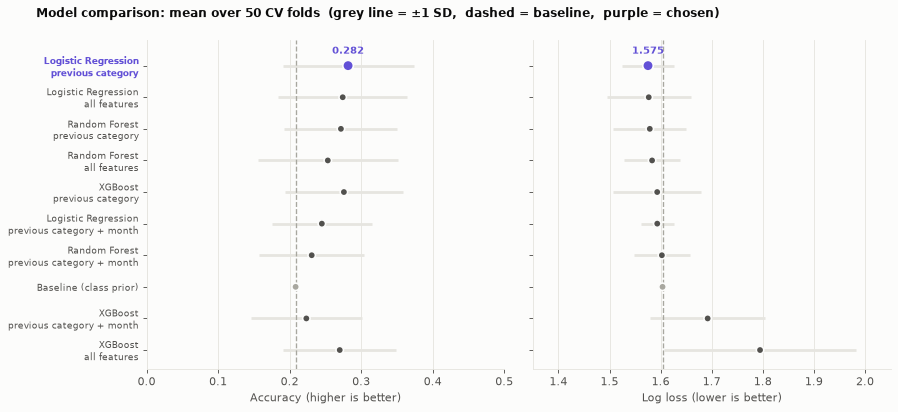

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
order = cv.index[::-1]  # best (lowest log loss) at the top
y = np.arange(len(order))
for ax, metric, label in [(axes[0], "accuracy", "Accuracy (higher is better)"),
                          (axes[1], "log_loss", "Log loss (lower is better)")]:
    mean, std = cv.loc[order, f"{metric}_mean"], cv.loc[order, f"{metric}_std"]
    colors = [CHOSEN if n == chosen else MUTED if n == baseline else INK_2 for n in order]
    ax.hlines(y, mean - std, mean + std, color=GRID, lw=2.5, zorder=1)
    ax.scatter(mean, y, c=colors, s=[90 if n == chosen else 45 for n in order], zorder=3,
               edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(cv.loc[baseline, f"{metric}_mean"], color=MUTED, ls="--", lw=1.2, zorder=2)
    ax.text(mean[chosen], y[list(order).index(chosen)] + 0.38, f"{mean[chosen]:.3f}",
            ha="center", fontsize=9, color=CHOSEN, fontweight="bold")
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [n.replace(" | ", "\n") for n in order], fontsize=8.5)
axes[0].set_xlim(0, 0.5)
axes[1].set_xlim(1.35, 2.05)
for tick in axes[0].get_yticklabels():
    if tick.get_text().replace("\n", " | ") == chosen:
        tick.set_color(CHOSEN)
        tick.set_fontweight("bold")
for ax in axes:
    ax.set_ylim(-0.6, len(order) - 0.2)
fig.suptitle("Model comparison: mean over 50 CV folds  (grey line = ±1 SD,  dashed = baseline,  purple = chosen)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.subplots_adjust(wspace=0.08, top=0.9)
save(fig, "cv_comparison")

**Interpretation:**
- **Every model clears the baseline on accuracy, but only barely.** The best mean accuracies are 25–28% against 20.8% for the baseline. On log loss, seven of the nine models beat the baseline (1.604), but by at most 0.03. XGBoost on all features is clearly *worse* (1.795): it is confidently wrong.
- **The spread across folds (grey lines, ±7–10 accuracy points) dwarfs the gaps between models.** On 24-row validation folds one extra correct prediction moves accuracy by 4 points, so no model is clearly best. This is why the selection uses log loss and 50 folds.
- **Logistic Regression on the previous category alone** has the lowest log loss (1.575) and the highest accuracy (28.2%). The all-features Logistic Regression is almost tied (1.577) and has a higher macro F1 (0.268 vs 0.241). Section 5 breaks this tie: it shows which of the two holds up on new customers.

## 4. Held-out test set (30 rows, scored once)

In [7]:
y_all, idx_test = result["y"], result["idx_test"]
y_test = y_all[idx_test]
test = result["test_summary"].loc[cv.index]  # same order as the CV table
display(test.round(3))

# 95% bootstrap interval for test accuracy: how precise is a 30-row test set?
rng = np.random.default_rng(config.RANDOM_STATE)
boot = [rng.integers(0, len(y_test), len(y_test)) for _ in range(5000)]
for name in [chosen, baseline]:
    hit = result["test_proba"][name].argmax(axis=1) == y_test
    lo, hi = np.percentile([hit[b].mean() for b in boot], [2.5, 97.5])
    print(f"{name:<42} accuracy {hit.mean():.3f}   95% CI [{lo:.2f}, {hi:.2f}]")

,accuracy,f1_macro,log_loss,top3_accuracy
Logistic Regression | previous category,0.267,0.225,1.655,0.567
Logistic Regression | all features,0.200,0.195,1.759,0.533
Random Forest | previous category,0.267,0.218,1.708,0.567
Random Forest | all features,0.200,0.192,1.678,0.533
XGBoost | previous category,0.267,0.225,1.724,0.500
Logistic Regression | previous category + month,0.267,0.258,1.598,0.667
Random Forest | previous category + month,0.233,0.227,1.645,0.633
Baseline (class prior),0.233,0.076,1.601,0.633
XGBoost | previous category + month,0.267,0.264,1.686,0.600
XGBoost | all features,0.300,0.272,2.019,0.633


Logistic Regression | previous category    accuracy 0.267   95% CI [0.10, 0.43]
Baseline (class prior)                     accuracy 0.233   95% CI [0.10, 0.40]


              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       1.00      0.17      0.29         6
 Electronics       0.28      0.71      0.40         7
   Groceries       0.50      0.20      0.29         5
      Sports       0.17      0.14      0.15         7

    accuracy                           0.27        30
   macro avg       0.39      0.24      0.23        30
weighted avg       0.39      0.27      0.23        30

Predicted classes on the test set: {'Electronics': 18, 'Sports': 6, 'Books': 3, 'Groceries': 2, 'Clothing': 1}


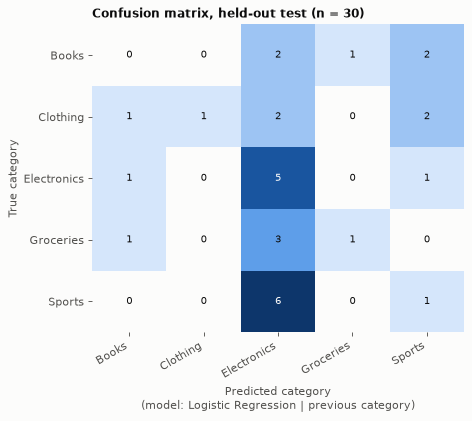

In [8]:
pred_test = result["test_proba"][chosen].argmax(axis=1)
print(classification_report(y_test, pred_test, target_names=tp.CLASSES, zero_division=0))
print("Predicted classes on the test set:",
      pd.Series(np.array(tp.CLASSES)[pred_test]).value_counts().to_dict())

cm = pd.DataFrame(confusion_matrix(y_test, pred_test, labels=tp.LABELS), index=tp.CLASSES, columns=tp.CLASSES)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap(ax, cm, f"Confusion matrix, held-out test (n = {len(y_test)})", vmax=cm.values.max(), fmt="{:d}")
ax.set_xlabel(f"Predicted category\n(model: {chosen})")
ax.set_ylabel("True category")
save(fig, "confusion_matrix")

**Interpretation:**
- The chosen model scores **26.7% accuracy and macro F1 0.225** on the test set, against 23.3% for the baseline. The bootstrap intervals (about 10–43% vs 10–40%) **overlap almost completely**, so a 30-row test set cannot prove the difference. Its log loss (1.655) is slightly *worse* than the baseline's here. This is not surprising for a gain this small, but it should be reported.
- **The confusion matrix shows the weakness: 18 of 30 test predictions are Electronics.** Half of all rows are first purchases with `cust_prev_category = no_history`. The model gives every such row the same answer, the category most often bought first (Electronics, 28% of first purchases). This produces high recall for Electronics (5/7) and zero for Books.
- **Note:** XGBoost on all features has the best single test accuracy (30%) but by far the worst log loss (2.02). It is right a little more often and very overconfident when wrong. With only 30 rows, one model "winning" the test set is mostly luck, which is why selection never looks at the test set.

## 5. Generalisation to unseen customers

Stratified CV puts transactions from the same customer in both training and validation folds. A model can then partly "recognise" a customer from their constant social-profile values instead of learning purchase patterns. **Customer-grouped CV** keeps each customer entirely in one fold, which is the harder and more honest test.

,accuracy_mean,f1_macro_mean,log_loss_mean,top3_accuracy_mean
Logistic Regression | previous category,0.294,0.267,1.595,0.640
Logistic Regression | all features,0.213,0.194,1.680,0.628
Random Forest | previous category,0.287,0.260,1.604,0.640
Random Forest | all features,0.167,0.156,1.644,0.560
XGBoost | previous category,0.313,0.276,1.608,0.666
Logistic Regression | previous category + month,0.234,0.216,1.588,0.687
Random Forest | previous category + month,0.241,0.221,1.592,0.701
Baseline (class prior),0.227,0.074,1.602,0.640
XGBoost | previous category + month,0.220,0.203,1.673,0.667
XGBoost | all features,0.213,0.190,1.962,0.566


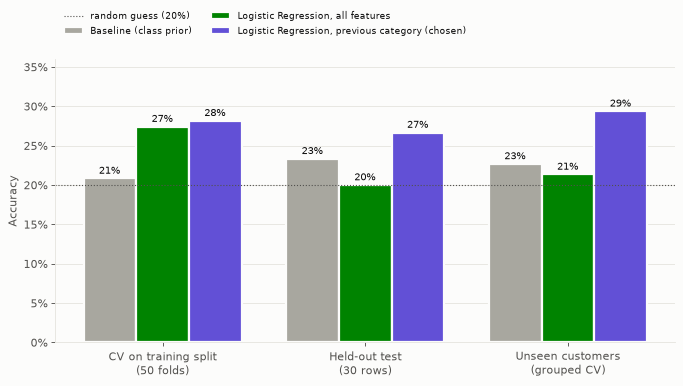

In [9]:
grp = result["grouped_cv"].loc[cv.index]
display(grp[[f"{m}_mean" for m in METRICS]].round(3))

all_feats = "Logistic Regression | all features"
show = [baseline, all_feats, chosen]
views = {
    "CV on training split\n(50 folds)": [cv.loc[n, "accuracy_mean"] for n in show],
    "Held-out test\n(30 rows)": [test.loc[n, "accuracy"] for n in show],
    "Unseen customers\n(grouped CV)": [grp.loc[n, "accuracy_mean"] for n in show],
}
labels = ["Baseline (class prior)", "Logistic Regression, all features", "Logistic Regression, previous category (chosen)"]
colors = [MUTED, ALL_FEATS, CHOSEN]

fig, ax = plt.subplots(figsize=(10, 4.6))
x, w = np.arange(len(views)), 0.26
for k, (label, color) in enumerate(zip(labels, colors)):
    vals = [v[k] for v in views.values()]
    bars = ax.bar(x + (k - 1) * w, vals, w, color=color, label=label, edgecolor=SURFACE, linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f"{v:.0%}", ha="center", fontsize=9, color=INK)
ax.axhline(0.2, color=INK_2, ls=":", lw=1, label="random guess (20%)")
ax.set_xticks(x, list(views))
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 0.36)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncols=2, fontsize=8.5, bbox_to_anchor=(0, 1.2))
save(fig, "generalisation")

**Interpretation:** this is the decisive comparison.
- **The all-features models collapse on unseen customers.** Logistic Regression with all features drops from 27% (CV) to 21%, below the 23% baseline. The Random Forest (17%) and XGBoost (21%) do the same. Their CV score came from recognising customers by their social-profile values, not from patterns that transfer.
- **The previous-category model holds up.** It scores **29.4%** accuracy and macro F1 0.267 on unseen customers, above the baseline in every one of the three views. Its gain is small but **consistent**, which is the most you can ask of 150 rows.
- This also answers the near-tie in Section 3: the simpler model is the right choice.

## 6. What the model learned

### 6.1 Category transitions
The chosen model uses a single input: the customer's most frequent earlier category. Its behaviour is therefore fully described by one table, P(next category | previous category). The left heatmap below shows the raw frequencies in the data; the right one shows the probabilities the final model actually outputs.

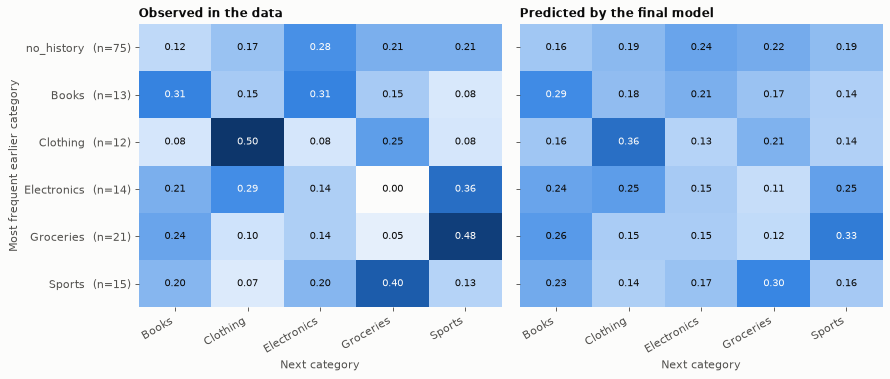

In [10]:
final = result["final_model"]
empirical = pd.crosstab(df["cust_prev_category"], df[dm.TARGET], normalize="index").reindex(
    index=[dm.NO_HISTORY] + dm.CATEGORIES, columns=dm.CATEGORIES)
n_prev = df["cust_prev_category"].value_counts()
probe = pd.concat([tp.customer_feature_row(187, df=df)] * len(empirical), ignore_index=True)
probe["cust_prev_category"] = empirical.index
learned = pd.DataFrame(final.predict_proba(probe), index=empirical.index, columns=tp.CLASSES)

row_labels = [f"{c}  (n={n_prev[c]})" for c in empirical.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
heatmap(axes[0], empirical.set_axis(row_labels), "Observed in the data", vmax=0.5)
heatmap(axes[1], learned.set_axis(row_labels), "Predicted by the final model", vmax=0.5)
axes[0].set_ylabel("Most frequent earlier category")
for ax in axes:
    ax.set_xlabel("Next category")
fig.subplots_adjust(wspace=0.05)
save(fig, "learned_transitions")

**Interpretation:**
- **The data has real, if noisy, habits:** Clothing buyers tend to buy Clothing again (50%); Groceries is most often followed by Sports (48%) and Sports by Groceries (40%); Books buyers return to Books or Electronics (31% each).
- **The model reproduces each of these patterns but shrinks them towards 20%** (e.g. Clothing → Clothing 36%, Groceries → Sports 33%). That is the regularisation (C = 0.3) doing its job: each row rests on only 12–21 transactions, so trusting the raw 50% would overfit. This shrinkage is also why the log loss is only slightly better than the baseline. The model is rarely confident.
- **First purchases get a near-uniform distribution**, with Electronics on top (24%). This is the single answer behind the 18 Electronics predictions in Section 4.
- A simple "buy the same category again" rule would be right only **20%** of the time on rows with history, which is no better than random. The useful signal is in the *transitions*, not in repetition.

### 6.2 Which features carry signal? (permutation importance)

To check that dropping the other features was justified, the **all-features Random Forest** is refit on each customer-grouped training fold. Each column of the held-out fold is then shuffled 20 times. **Importance** = the increase in log loss when the column is shuffled, averaged over the 5 folds. A value above 0 means the column helps on unseen customers; a value below 0 means the model is better off without it.

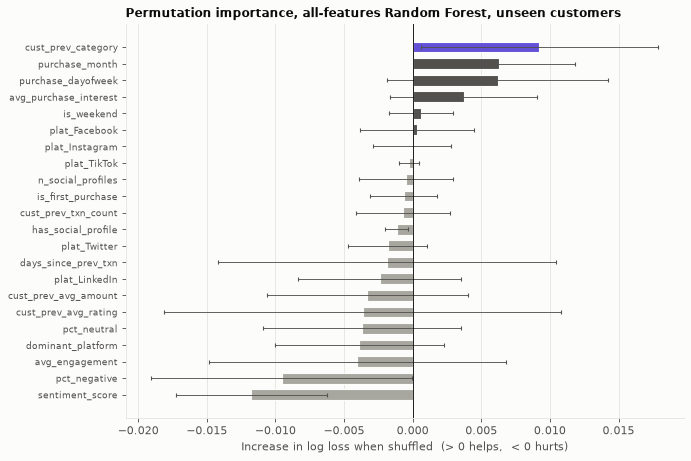

,mean,sd
cust_prev_category,0.0092,0.0087
purchase_month,0.0063,0.0056
purchase_dayofweek,0.0062,0.0080
avg_purchase_interest,0.0037,0.0054
is_weekend,0.0006,0.0023


In [11]:
rf_all = result["tuned"]["Random Forest | all features"]
X_all = result["X"]
neg_log_loss = lambda est, X, y: -log_loss(y, tp._full_proba(est, X), labels=tp.LABELS)
imps = []
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
for tr, te in splitter.split(X_all, y_all, df["customer_id"]):
    model = clone(rf_all).fit(X_all.iloc[tr], y_all[tr])
    pi = permutation_importance(model, X_all.iloc[te], y_all[te], scoring=neg_log_loss,
                                n_repeats=20, random_state=config.RANDOM_STATE, n_jobs=-1)
    imps.append(pi.importances_mean)
imp = pd.DataFrame(imps, columns=tp.FEATURES)
imp = pd.DataFrame({"mean": imp.mean(), "sd": imp.std()}).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6.4))
colors = [CHOSEN if f == "cust_prev_category" else INK_2 if m > 0 else MUTED for f, m in imp["mean"].items()]
ax.barh(imp.index, imp["mean"], color=colors, height=0.65, edgecolor=SURFACE, linewidth=1)
ax.errorbar(imp["mean"], imp.index, xerr=imp["sd"], fmt="none", ecolor=INK_2, elinewidth=0.8, capsize=2)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Increase in log loss when shuffled  (> 0 helps,  < 0 hurts)")
ax.set_title("Permutation importance, all-features Random Forest, unseen customers", loc="left")
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
save(fig, "permutation_importance")
imp.sort_values("mean", ascending=False).head(5).round(4)

**Interpretation:**
- **`cust_prev_category` is the most useful feature**, which agrees with the EDA and with the model selection.
- **Date features help slightly** (`purchase_month`, `purchase_dayofweek`), but their error bars cross zero. In Section 3, adding month to the previous category did not improve CV performance, so it was rightly left out.
- **Most social-profile features are at or below zero**, and **`sentiment_score` clearly hurts** (its whole error bar is below zero), and `pct_negative` very likely does too. On customers the model has not seen, the profile tells it nothing reliable about what they will buy. This is a result of the merge, not a flaw in it: notebook 01 showed that no profile feature separates categories, and this confirms it from the model's side.

## 7. Final model and `predict_for_customer`

The chosen configuration was refit on all 150 rows and saved by `tp.save()`:
- `models/product_model.joblib`, the full scikit-learn pipeline (preprocessing + classifier). It takes a row with all input columns and selects its own.
- `models/product_model_meta.json`, which holds the algorithm, feature set, class order, the excluded features with reasons, and every metric reported above.

**Use in the app (step 2 of the flow).** After the face model identifies a member, the app looks up `config.MEMBER_TO_CUSTOMER[member]` and calls:

```python
from src.train_product_model import predict_for_customer
category, probabilities = predict_for_customer(customer_id)   # held until the voice check passes
```

`customer_feature_row` builds the input for the customer's **next** purchase. The history covers all of their recorded transactions, the social profile is unchanged, and the date is `as_of`. `as_of` defaults to the day after the last date in the data (2024-05-30), which keeps the demo reproducible and keeps the gap since the last purchase within the range seen in training.

In [12]:
meta = json.loads(config.PRODUCT_META_PATH.read_text())
print(json.dumps({k: meta[k] for k in ["algorithm", "feature_set", "params", "classes", "training_rows", "data_as_of"]}, indent=1))
print(json.dumps(meta["metrics"], indent=1))

{
 "algorithm": "Logistic Regression",
 "feature_set": "previous category",
 "params": {
  "C": 0.3
 },
 "classes": [
  "Books",
  "Clothing",
  "Electronics",
  "Groceries",
  "Sports"
 ],
 "training_rows": 150,
 "data_as_of": "2024-05-29"
}
{
 "cv_5x10_train_split": {
  "accuracy": 0.2817,
  "f1_macro": 0.2414,
  "log_loss": 1.5753,
  "top3_accuracy": 0.7067
 },
 "held_out_test": {
  "rows": 30,
  "accuracy": 0.2667,
  "f1_macro": 0.2251,
  "log_loss": 1.6549,
  "top3_accuracy": 0.5667
 },
 "customer_grouped_cv": {
  "accuracy": 0.2937,
  "f1_macro": 0.2672,
  "log_loss": 1.5951,
  "top3_accuracy": 0.6401
 },
 "baseline_class_prior": {
  "cv_accuracy": 0.2083,
  "cv_log_loss": 1.6037,
  "test_accuracy": 0.2333
 }
}


In [13]:
rows = []
for member, cid in config.MEMBER_TO_CUSTOMER.items():
    hist = df[df["customer_id"] == cid].sort_values("purchase_date")[dm.TARGET].tolist()
    category, probs = tp.predict_for_customer(cid)
    top3 = list(probs.items())[:3]
    rows.append({"member": member, "customer_id": cid, "purchase history": " → ".join(hist),
                 "previous category used": dm._prev_mode(hist), "prediction": category,
                 "top 3": ", ".join(f"{c} {p:.0%}" for c, p in top3)})
members = pd.DataFrame(rows).set_index("member")
members

,customer_id,purchase history,previous category used,prediction,top 3
member,,,,,
hassan,187,Sports → Groceries → Sports → Sports → Books,Sports,Groceries,"Groceries 30%, Books 23%, Electronics 17%"
emma,101,Books → Groceries → Books → Books,Books,Books,"Books 29%, Electronics 21%, Clothing 18%"
parfait,114,Electronics → Clothing → Clothing → Clothing,Clothing,Clothing,"Clothing 36%, Groceries 21%, Books 16%"
peter,120,Groceries → Sports → Groceries,Groceries,Sports,"Sports 33%, Books 26%, Clothing 15%"


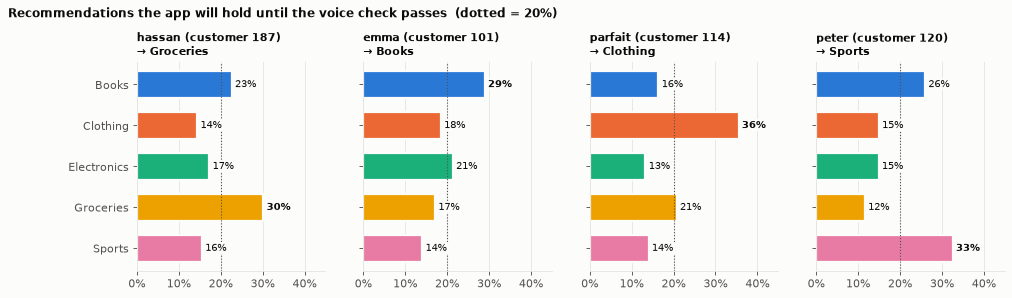

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True)
for ax, (member, cid) in zip(axes, config.MEMBER_TO_CUSTOMER.items()):
    category, probs = tp.predict_for_customer(cid)
    vals = [probs[c] for c in dm.CATEGORIES][::-1]
    cats = dm.CATEGORIES[::-1]
    ax.barh(cats, vals, color=[CATEGORY_COLORS[c] for c in cats], height=0.65, edgecolor=SURFACE, linewidth=2)
    for c, v in zip(cats, vals):
        ax.text(v + 0.008, c, f"{v:.0%}", va="center", fontsize=9, color=INK, zorder=3,
                fontweight="bold" if c == category else "normal",
                bbox={"boxstyle": "square,pad=0.1", "fc": SURFACE, "ec": "none"})
    ax.axvline(0.2, color=INK_2, ls=":", lw=1, zorder=1)
    ax.set_title(f"{member} (customer {cid})\n→ {category}", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 0.45)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False)
fig.suptitle("Recommendations the app will hold until the voice check passes  (dotted = 20%)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", y=1.08)
save(fig, "member_predictions")

In [15]:
# Robustness checks the app relies on
fresh = tp.customer_feature_row(187, df=df)
assert list(fresh.columns) == tp.FEATURES and fresh.notna().all(axis=None)
first_timer = int(df.loc[df.groupby("customer_id")["customer_id"].transform("size") == 1, "customer_id"].iloc[0])
print(f"One-purchase customer {first_timer}:", tp.predict_for_customer(first_timer)[0])
try:
    tp.predict_for_customer(999)
except KeyError as err:
    print("Unknown customer ->", err)

One-purchase customer 151: Groceries
Unknown customer -> 'customer_id 999 is not in the merged dataset'


**Interpretation:** the four simulated customers get **four different recommendations**, each following that customer's dominant earlier category and the transition table in Section 6.1. For example, Hassan's customer (187) bought mostly Sports, and Sports is most often followed by Groceries. The top category always gets 29–36%, well above 20% but far from certain. Showing the **top 3** is the honest way to present this in the app. The true category is in the model's top 3 about 71% of the time in CV (65% for the baseline), but only 64% for unseen customers, the same as the baseline. So the ranking helps most for customers with a purchase history, which all four demo customers have. An unknown `customer_id` raises a clear `KeyError` that the app can turn into a message.

---
# Part B · Facial recognition model
**Owner:** Emma Tiffany Umwari · **Code:** [`src/train_face_model.py`](../src/train_face_model.py)

## 8. Facial recognition model

**Task:** identify which of the 4 members is in a photo, and **reject anyone else**. This is the first gate of the app.

**Data:** `features/image_features.csv` from notebook 02: 108 rows = 12 source photos (4 members × 3 expressions) × (original + 8 augmentations). Features are a 128-d **SFace embedding** (a pretrained face-recognition network), a 48-bin colour histogram and a 10-bin LBP texture histogram.

| Step | Choice | Why |
|---|---|---|
| Split | **Leave-one-source-photo-out** (12 folds). A photo and its 8 augmented copies are always held out together. | Augmented copies of a test photo in training would leak. Every fold tests an expression the model has never seen for that member. |
| Candidates | Logistic Regression, linear SVM (Platt-calibrated), Random Forest × {embedding (128), embedding + colour/texture (186)} | A linear baseline (LR) compared with a margin-based (SVM) and a tree-based (RF) model. |
| Selection | Lowest held-out **log loss**. A difference below 0.001 is a tie, won by the smaller feature set. | Accuracy cannot separate models that are all correct; log loss rewards being confidently right. |
| Strangers | **Cosine similarity** to the predicted member's mean embedding must reach a threshold (Section 8.2). | A 4-class classifier always names one of the 4 members. |

In [16]:
%%time
face = tf.train_and_evaluate(verbose=False)
tf.save(face)
print("Chosen:", face["chosen"])
face["comparison"].drop(columns=["algorithm", "feature_set"]).round(4)

Chosen: Logistic Regression | embedding
CPU times: user 25.1 s, sys: 1.15 s, total: 26.3 s
Wall time: 20.8 s


,n_features,accuracy,f1_macro,log_loss
model,,,,
Logistic Regression | embedding,128,1.0,1.0,0.0072
Logistic Regression | embedding + colour/texture,186,1.0,1.0,0.0069
SVM (linear) | embedding + colour/texture,186,1.0,1.0,0.0559
SVM (linear) | embedding,128,1.0,1.0,0.0852
Random Forest | embedding,128,1.0,1.0,0.2371
Random Forest | embedding + colour/texture,186,1.0,1.0,0.2651


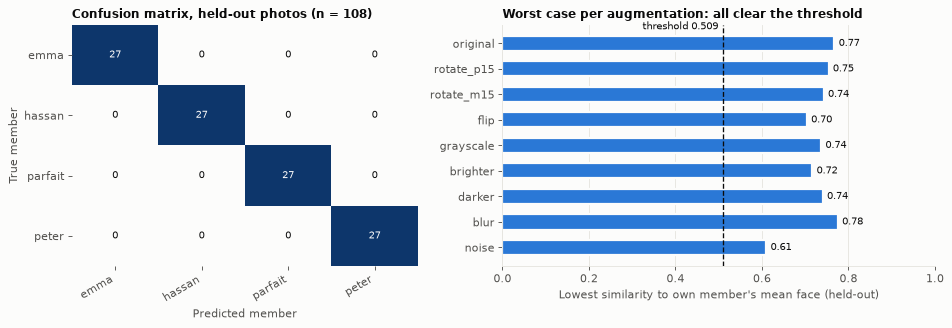

              precision    recall  f1-score   support

        emma      1.000     1.000     1.000        27
      hassan      1.000     1.000     1.000        27
     parfait      1.000     1.000     1.000        27
       peter      1.000     1.000     1.000        27

    accuracy                          1.000       108
   macro avg      1.000     1.000     1.000       108
weighted avg      1.000     1.000     1.000       108



In [17]:
classes = face["classes"]
cm = pd.DataFrame(confusion_matrix(face["y"], face["oof_pred"], labels=classes), index=classes, columns=classes)
per_aug = face["per_augmentation"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
heatmap(axes[0], cm, "Confusion matrix, held-out photos (n = 108)", vmax=cm.values.max(), fmt="{:d}")
axes[0].set_xlabel("Predicted member")
axes[0].set_ylabel("True member")

ax = axes[1]
order = per_aug.index[::-1]
ax.barh(order, per_aug.loc[order, "min_similarity"], color=GENUINE, height=0.6, edgecolor=SURFACE, linewidth=2)
ax.axvline(face["threshold"], color=INK, ls="--", lw=1.2)
ax.text(face["threshold"] - 0.01, len(order) - 0.45, f"threshold {face['threshold']:.3f}", ha="right",
        fontsize=9, color=INK)
for a, v in zip(order, per_aug.loc[order, "min_similarity"]):
    ax.text(v + 0.01, a, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Lowest similarity to own member's mean face (held-out)")
ax.set_title("Worst case per augmentation: all clear the threshold", loc="left")
fig.tight_layout()
save(fig, "confusion_and_augmentations", prefix="face")
print(classification_report(face["y"], face["oof_pred"], digits=3))

**Interpretation:**
- **Every candidate identifies every held-out photo correctly** (accuracy and macro F1 = 1.0), including rotated, flipped, darkened, blurred and noisy copies. The SFace network was pretrained on millions of faces, so 4 people under similar conditions are easy for it. The classifier on top only has to draw lines between 4 well-separated clusters (notebook 02, Section 7 showed the same separation).
- Log loss is what separates the candidates. **Logistic Regression on the embedding** is the most confident when right (log loss ≈ 0.007). Adding colour/texture changes it by less than 0.001, so the simpler embedding-only model is kept. Notebook 02 showed that colour histograms mostly track lighting and background, not identity.
- **Robustness:** the hardest augmentation is Gaussian noise (lowest similarity 0.61), still well above the threshold.
- **Caveat:** 12 photos per team, taken in one session each, is a small and easy test. Accuracy in the wild (other cameras, glasses, poor light) would be lower. A perfect score here means "works for this demo", not "solved".

### 8.1 Rejecting faces that are not in the team

The app must deny access to a stranger. Two sets of strangers are used:
- **Simulated (used to set the threshold):** leave-one-member-out. Each member in turn is removed from training and their 27 rows are scored against the remaining three. A real person the model has never seen is a fair stand-in for a non-member.
- **Real non-members (used only to test the threshold):** 3 photos of one non-member in `data/unauthorized/faces/` (27 rows with augmentations; notebook 02, Section 8). They play no part in training or in choosing the threshold.

Two candidate rejection scores:
- **Classifier confidence**, `max(predict_proba)`;
- **Cosine similarity** between the face's embedding and the predicted member's mean (enrolled) embedding.

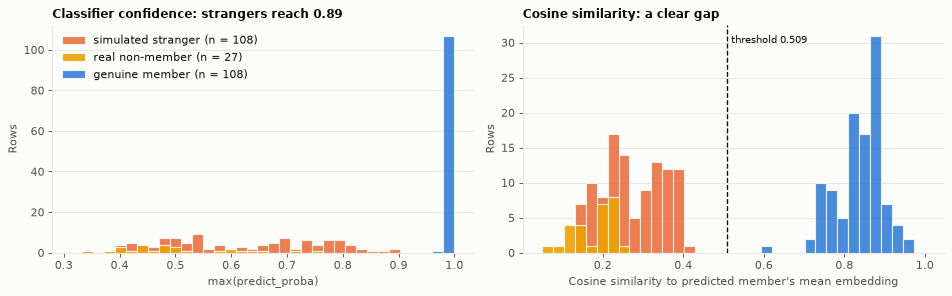

Genuine similarity:  min 0.610
Stranger similarity: max 0.409
Threshold 0.509: genuine accepted 100%, simulated strangers rejected 100%
Real non-members: 100% of 27 rows rejected; highest similarity 0.249, highest classifier confidence 0.747


,closest_member,max_confidence,max_similarity,rows_rejected
neutral,emma,0.747,0.237,9
smiling,hassan,0.484,0.140,9
surprised,hassan,0.517,0.249,9


In [18]:
lr = tf.candidates()["Logistic Regression"]
emb, y_face = face["df"][tf.ip.EMB_COLS].to_numpy(), face["y"]
stranger_conf = np.concatenate([clone(lr).fit(emb[y_face != m], y_face[y_face != m]).predict_proba(emb[y_face == m]).max(axis=1)
                                for m in classes])
genuine_conf = face["oof_proba"].max(axis=1)

# Real non-members, scored by the final model (never trained on them)
_, unknown_faces = tf.load_data()
fm = tf.load_model()
u_proba = fm["model"].predict_proba(unknown_faces[fm["feature_columns"]].to_numpy())
u_member = np.array(fm["classes"])[u_proba.argmax(axis=1)]
real_conf = u_proba.max(axis=1)
real_sim = tf.similarity(unknown_faces[tf.ip.EMB_COLS].to_numpy(), fm["centroids"], u_member)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (gen, strg, real, title, thr) in zip(axes, [
        (genuine_conf, stranger_conf, real_conf, "Classifier confidence: strangers reach 0.89", None),
        (face["genuine_similarity"], face["stranger_similarity"], real_sim, "Cosine similarity: a clear gap", face["threshold"])]):
    bins = np.linspace(min(gen.min(), strg.min(), real.min()) - 0.02, 1.0, 36)
    ax.hist(strg, bins=bins, color=STRANGER, alpha=0.85, label=f"simulated stranger (n = {len(strg)})", edgecolor=SURFACE, linewidth=1)
    ax.hist(real, bins=bins, color=OTHER_MEMBER, alpha=0.9, label=f"real non-member (n = {len(real)})", edgecolor=SURFACE, linewidth=1)
    ax.hist(gen, bins=bins, color=GENUINE, alpha=0.85, label=f"genuine member (n = {len(gen)})", edgecolor=SURFACE, linewidth=1)
    if thr is not None:
        ax.axvline(thr, color=INK, ls="--", lw=1.2)
        ax.text(thr + 0.01, ax.get_ylim()[1] * 0.92, f"threshold {thr:.3f}", fontsize=9, color=INK)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Rows")
    ax.grid(axis="x", visible=False)
axes[0].set_xlabel("max(predict_proba)")
axes[1].set_xlabel("Cosine similarity to predicted member's mean embedding")
axes[0].legend(loc="upper left")
fig.tight_layout()
save(fig, "stranger_rejection", prefix="face")

print(f"Genuine similarity:  min {face['genuine_similarity'].min():.3f}")
print(f"Stranger similarity: max {face['stranger_similarity'].max():.3f}")
print(f"Threshold {face['threshold']}: genuine accepted {face['genuine_accept_rate']:.0%}, "
      f"simulated strangers rejected {face['stranger_reject_rate']:.0%}")
print(f"Real non-members: {face['unauthorized']['reject_rate']:.0%} of {face['unauthorized']['rows']} rows rejected; "
      f"highest similarity {real_sim.max():.3f}, highest classifier confidence {real_conf.max():.3f}")
pd.DataFrame({"closest member": u_member, "confidence": real_conf, "similarity": real_sim,
              "rejected": real_sim < face["threshold"]}, index=unknown_faces["image_id"]).groupby(
    unknown_faces["source_image"].to_numpy()).agg(
    closest_member=("closest member", lambda s: s.mode()[0]), max_confidence=("confidence", "max"),
    max_similarity=("similarity", "max"), rows_rejected=("rejected", "sum")).round(3)

**Interpretation:**
- **Classifier confidence is the wrong signal.** A softmax always spreads 100% across the known members, so a stranger who looks a little like one member can get 0.6–0.9 confidence. No confidence threshold would reject strangers without also hurting members.
- **Similarity to the enrolled face separates the groups completely.** Every held-out genuine photo scores ≥ 0.61; every simulated stranger scores ≤ 0.41. The threshold (0.509) sits in the middle of this gap, leaving a margin of about 0.1 on each side.
- So the app uses **two checks**: the classifier names the closest member, and the similarity check confirms it is really them. Both are in `identify_face()`.
- **The real non-member confirms it:** all 27 rows are rejected, with similarity at most about 0.25, far below the threshold. The classifier alone would have named Emma or Hassan with up to about 0.75 confidence, so a confidence threshold would have needed to sit above 0.75 just for this one stranger. The real test is small (one person, 3 photos), but it agrees with the 108 simulated stranger rows.

### 8.2 Final model and `identify_face`

`tf.save()` refits Logistic Regression on all 108 rows and stores the model, the 4 enrolled mean embeddings and the threshold in `models/face_model.joblib`, plus metrics in `models/face_model_meta.json`. The app calls:

```python
from src.train_face_model import identify_face
result = identify_face("photo.jpg")   # {"accepted", "member", "similarity", "reason", ...}
```

In [19]:
demo_faces = [config.IMAGES_DIR / "peter" / "peter_smiling_01.jpg",
              config.AUGMENTED_IMAGES_DIR / "emma_neutral_01__noise.jpg",
              config.AUGMENTED_IMAGES_DIR / "hassan_surprised_01__rotate_m15.jpg"]
pd.DataFrame([{"image": p.name, **{k: v for k, v in tf.identify_face(p).items() if k != "probabilities"}}
              for p in demo_faces]).set_index("image")

,accepted,member,closest_member,confidence,similarity,threshold,reason
image,,,,,,,
peter_smiling_01.jpg,True,peter,peter,0.998,0.934,0.509,face recognised
emma_neutral_01__noise.jpg,True,emma,emma,0.998,0.876,0.509,face recognised
hassan_surprised_01__rotate_m15.jpg,True,hassan,hassan,0.998,0.932,0.509,face recognised


---
# Part C · Voiceprint verification model
**Owner:** Parfait Shema Semana · **Code:** [`src/train_voice_model.py`](../src/train_voice_model.py), using Parfait's [`Audio_features/audio_pipeline.py`](../Audio_features/audio_pipeline.py)

## 9. Voiceprint verification model

**Task:** confirm that the voice belongs to **the member the face model recognised**. This is a *verification* task: the face step makes a claim and the voice must confirm it. A clip is accepted for member *m* only if the classifier's top prediction is *m* **and** P(*m* | clip) ≥ threshold.

**Data:** `Audio_features/data/audio_features.csv` (Parfait): 48 rows = 8 recordings (4 members × 2 phrases, **one take each**) × (original + 5 augmentations: pitch ±2 semitones, time stretch ×1.15 / ×0.85, noise + gain + shift). 64 features: mean and std of 13 MFCCs and 13 delta-MFCCs, spectral roll-off, centroid, bandwidth, zero-crossing rate, RMS energy and pitch (YIN).

| Step | Choice | Why |
|---|---|---|
| Split | **Leave-one-recording-out** (8 folds); augmented copies held out with their source | No leakage. With one take per phrase, each fold trains on the speaker's *other* phrase only, so this is a strict **text-independent** test. |
| Candidates | Logistic Regression, Random Forest, XGBoost on the 64 features | A linear baseline, a bagged tree ensemble and a boosted one. |
| Selection | Lowest held-out log loss | Same rule as the other two models. |
| Threshold | Minimise *false-reject rate + 2 × false-accept rate* over held-out verification attempts (Section 9.1) | Approving a payment for the wrong person is worse than asking a member to repeat the phrase. |

In [20]:
%%time
voice = tv.train_and_evaluate(verbose=False)
tv.save(voice)
print("Chosen:", voice["chosen"])
voice["comparison"].round(4)

Chosen: XGBoost
CPU times: user 43.9 s, sys: 793 ms, total: 44.7 s
Wall time: 19.1 s


,accuracy,f1_macro,log_loss
model,,,
XGBoost,0.6458,0.6408,0.9460
Logistic Regression,0.4167,0.4152,1.1355
Random Forest,0.3750,0.3642,1.3047


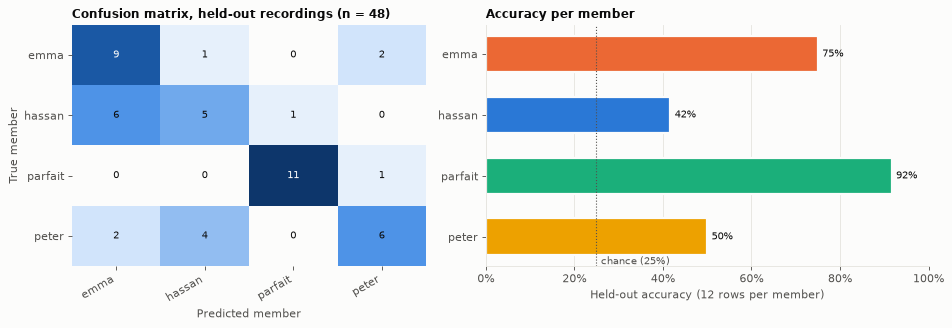

              precision    recall  f1-score   support

        emma      0.529     0.750     0.621        12
      hassan      0.500     0.417     0.455        12
     parfait      0.917     0.917     0.917        12
       peter      0.667     0.500     0.571        12

    accuracy                          0.646        48
   macro avg      0.653     0.646     0.641        48
weighted avg      0.653     0.646     0.641        48



,accuracy,accept_rate
augmentation,,
original,0.750,0.500
pitch_up,0.625,0.375
pitch_down,0.625,0.250
stretch_fast,0.500,0.500
stretch_slow,0.750,0.375
noise_gain_shift,0.625,0.625


In [21]:
vclasses = list(voice["classes"])
vpred = voice["oof_proba"].argmax(axis=1)
vcm = pd.DataFrame(confusion_matrix(voice["y"], vpred, labels=range(len(vclasses))), index=vclasses, columns=vclasses)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
heatmap(axes[0], vcm, "Confusion matrix, held-out recordings (n = 48)", vmax=vcm.values.max(), fmt="{:d}")
axes[0].set_xlabel("Predicted member")
axes[0].set_ylabel("True member")

ax = axes[1]
pm = voice["per_member"]["accuracy"]
ax.barh(pm.index[::-1], pm.values[::-1], color=[MEMBER_COLORS[m] for m in pm.index[::-1]], height=0.6,
        edgecolor=SURFACE, linewidth=2)
for m, v in zip(pm.index[::-1], pm.values[::-1]):
    ax.text(v + 0.01, m, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.axvline(0.25, color=INK_2, ls=":", lw=1)
ax.text(0.26, -0.45, "chance (25%)", fontsize=9, color=INK_2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Held-out accuracy (12 rows per member)")
ax.set_title("Accuracy per member", loc="left")
fig.tight_layout()
save(fig, "confusion_and_members", prefix="voice")
print(classification_report(voice["y"], vpred, target_names=vclasses, digits=3, zero_division=0))
voice["per_augmentation"].round(3)

**Interpretation:**
- **XGBoost** is the best of the three, with held-out accuracy ≈ 0.65 and log loss ≈ 0.95. The original Logistic Regression (Parfait's first model) scored 0.42 accuracy and 1.14 log loss on the same folds. Chance is 0.25 accuracy and log loss 1.39.
- It is **well above chance but far from the face model.** Each fold trains on a single phrase per speaker and tests on a *different* phrase, so the model must recognise the voice, not the words. Hand-crafted MFCC statistics from 1–3 seconds of one phrase describe the words almost as much as the speaker.
- **The weakness is the data, not the method.** Every member recorded each phrase **once**. With 8 recordings, each one is worth 12.5 percentage points of accuracy, so model differences are noisy. A pretrained speaker-embedding network (WeSpeaker ResNet34, the voice equivalent of SFace) was also tried. It was not clearly better on clips this short, so the simpler hand-crafted features were kept.
- Per member, Parfait's voice is recognised most reliably (11 of 12 rows) and Hassan's least: half of Hassan's held-out rows are mistaken for Emma.

### 9.1 Verification threshold: accepting members, rejecting impostors

Every held-out clip produces three kinds of verification attempt:
- **genuine**: the clip claims its own speaker (48 attempts);
- **other member**: the clip claims one of the other 3 members, the app's "identity mismatch" case (144 attempts);
- **simulated stranger**: leave-one-member-out. A member is removed from training, and their clips claim each of the other 3 members (144 attempts).

The score is P(claimed member), or 0 if the classifier's top pick is someone else.

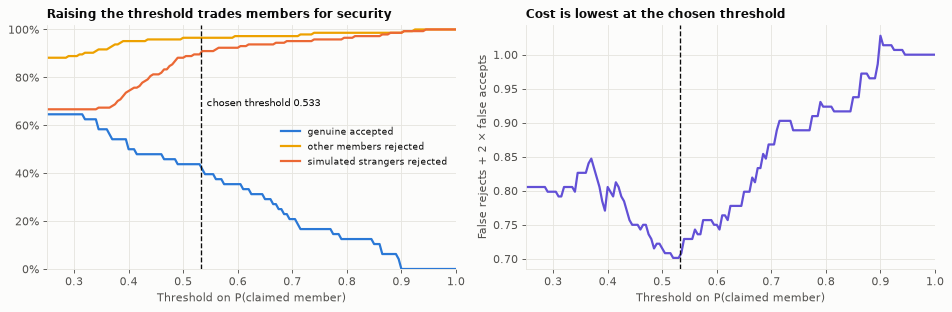

Threshold 0.533: genuine accepted 43.8%, other members rejected 96.5%, simulated strangers rejected 90.3%


In [22]:
ts = np.linspace(0.25, 1.0, 151)
curves = pd.DataFrame({
    "genuine accepted": [(voice["genuine"] >= t).mean() for t in ts],
    "other members rejected": [(voice["member_impostor"] < t).mean() for t in ts],
    "simulated strangers rejected": [(voice["stranger"] < t).mean() for t in ts],
}, index=ts)
thr = voice["threshold"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for (name, col), color in zip(curves.items(), [GENUINE, OTHER_MEMBER, STRANGER]):
    ax.plot(curves.index, col, color=color, lw=2, label=name)
ax.axvline(thr, color=INK, ls="--", lw=1.2)
ax.text(thr + 0.01, 0.68, f"chosen threshold {thr:.3f}", fontsize=9, color=INK)
ax.set_xlim(0.25, 1.0)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Threshold on P(claimed member)")
ax.set_title("Raising the threshold trades members for security", loc="left")
ax.legend(loc="center right", fontsize=8.5)

ax = axes[1]
cost = [tv.verification_cost(t, voice["genuine"], voice["member_impostor"], voice["stranger"]) for t in ts]
ax.plot(ts, cost, color=CHOSEN, lw=2)
ax.axvline(thr, color=INK, ls="--", lw=1.2)
ax.set_xlim(0.25, 1.0)
ax.set_xlabel("Threshold on P(claimed member)")
ax.set_ylabel("False rejects + 2 × false accepts")
ax.set_title("Cost is lowest at the chosen threshold", loc="left")
fig.tight_layout()
save(fig, "threshold_tradeoff", prefix="voice")

print(f"Threshold {thr}: genuine accepted {voice['genuine_accept_rate']:.1%}, other members rejected "
      f"{voice['member_impostor_reject_rate']:.1%}, simulated strangers rejected {voice['stranger_reject_rate']:.1%}")

**Real non-member voices.** Four clips from people outside the team (two in `data/unauthorized/voices/`, two of "Ketia" in `Audio_features/data/audio/unauthorized/`) are scored with the final model. The worst case is assumed: the stranger presents the face of whichever member they sound most like.

In [23]:
u = voice["unauthorized"]
real_voice = pd.DataFrame(u["per_clip"]).T
real_voice.index.name = "clip"
print(f"Real non-member clips rejected: {u['reject_rate']:.0%} of {u['clips']}")
real_voice

Real non-member clips rejected: 0% of 4


,closest_member,confidence,rejected
clip,,,
data/unauthorized/voices/approve.wav,hassan,0.853,False
data/unauthorized/voices/confirm.wav,hassan,0.584,False
Audio_features/data/audio/unauthorized/Ketia_approve.wav,parfait,0.856,False
Audio_features/data/audio/unauthorized/Ketia_comfirm.wav,parfait,0.934,False


**Can an `unknown` class learned from strangers fix this?** One option is to add the non-member clips as a fifth class. Fairly tested, that means training on one stranger and testing on the *other* (leave-one-stranger-out), since a new attacker will not be in the training data.

In [24]:
%%time
X_mem = voice["df"][voice["cols"]].to_numpy()
y_mem, g_mem = voice["y"], voice["df"]["source_file"].to_numpy()
rows = []
for i, clip in enumerate(tv.unauthorized_clips()):
    sig = tv.ap.load_clip(clip)
    for aug, s in ({"original": sig} | tv.ap.augment(sig, seed=100 + i)).items():
        rows.append({"speaker": "Ketia" if "Ketia" in clip.name else "stranger 2", **tv.ap.extract_features(s)})
strangers = pd.DataFrame(rows)
xgb = tv.candidates()["XGBoost"]
UNK = len(voice["classes"])

results = []
for held_out in strangers["speaker"].unique():
    tr = (strangers["speaker"] != held_out).to_numpy()
    X_unk, X_test = strangers.loc[tr, voice["cols"]].to_numpy(), strangers.loc[~tr, voice["cols"]].to_numpy()
    p = tv.fit_predict(xgb, np.r_[X_mem, X_unk], np.r_[y_mem, np.full(tr.sum(), UNK)], X_test, UNK + 1)
    rejected = (p.argmax(axis=1) == UNK) | (p[:, :UNK].max(axis=1) < thr)
    pg = np.zeros((len(y_mem), UNK + 1))                     # members: leave-one-recording-out again
    for src in np.unique(g_mem):
        te = g_mem == src
        pg[te] = tv.fit_predict(xgb, np.r_[X_mem[~te], X_unk], np.r_[y_mem[~te], np.full(tr.sum(), UNK)], X_mem[te], UNK + 1)
    genuine_ok = (pg.argmax(axis=1) == y_mem) & (pg[np.arange(len(y_mem)), y_mem] >= thr)
    results.append({"unknown class trained on": strangers.loc[tr, "speaker"].iloc[0], "tested on": held_out,
                    "held-out stranger rejected": rejected.mean(), "new genuine clips accepted": genuine_ok.mean()})
pd.DataFrame(results).round(2)

CPU times: user 44.4 s, sys: 586 ms, total: 45 s
Wall time: 17.4 s


,unknown class trained on,tested on,held-out stranger rejected,new genuine clips accepted
0,Ketia,stranger 2,0.25,0.19
1,stranger 2,Ketia,0.00,0.35


**Interpretation:**
- On held-out member data the chosen threshold looks reasonable. It **rejects about 97% of other members and 90% of simulated strangers**, but accepts only **about 44% of genuine clips it has never heard**. The 2:1 cost deliberately errs towards security, since a rejected member can simply repeat the phrase.
- **Real strangers are not rejected: 0 of 4 clips.** Each stranger sounds "most like" one member with 0.58–0.93 confidence: Ketia like Parfait, stranger 2 like Hassan. The simulated rate was too optimistic. Those simulations removed a member from a *smaller* model, while the final model is fitted to all 48 rows and is over-confident on anything new.
- **An `unknown` class does not generalise.** Trained on one stranger, it rejects few or none of the other stranger's clips, and it accepts fewer genuine clips. With two stranger voices there is nothing general to learn about "not a member".
- **Conclusion: on its own, the voice model cannot tell a new speaker from a member.** In the app, strangers are stopped by the **face gate**, which rejected 100% of real non-member faces (Section 8.1). The voice step adds two things: the **identity-match check**, which rejects 97% of other members' voices, and a check that the voice is a confident match at all. A stranger who could pass the face check would not be reliably stopped by their voice.
- **What this means for the demo:** the team's own recordings are accepted (≥ 0.95 confidence, augmented copies ≥ 0.85; Section 9.2). In scenario 4 (Parfait's face + stranger's voice), Ketia's voice would be **wrongly approved**, because it sounds like Parfait. Stranger 2's voice is denied, as an identity mismatch.
- **The fix is more data.** 3–4 more takes of each phrase per member would put the *same* phrase from the same speaker in training, so genuine scores rise while strangers' stay low. Rerunning `prepare_audio.py`, `audio_pipeline.py` and `src/train_voice_model.py` updates every number here.

### 9.2 Final model and `verify_voice`

`tv.save()` refits XGBoost on all 48 rows and stores it with the feature order, member classes and threshold in `models/voice_model.joblib`, plus metrics in `models/voice_model_meta.json`. The app calls it with the face result as the claimed identity:

```python
from src.train_voice_model import verify_voice
result = verify_voice("clip.wav", expected_member=face_member)   # {"approved", "reason", ...}
```

In [25]:
raw = config.AUDIO_PIPELINE_DIR / "data" / "audio" / "raw"
demo_voices = [(raw / "hassan_yes_approve_1.wav", "hassan"), (raw / "emma_confirm_transaction_1.wav", "emma"),
               (raw / "peter_yes_approve_1.wav", "parfait"),
               (config.UNAUTHORIZED_VOICES_DIR / "approve.wav", "parfait"),
               (tv.ap.UNAUTH_DIR / "Ketia_approve.wav", "parfait")]
pd.DataFrame([{"clip": p.name, "claimed (face)": m, **{k: v for k, v in tv.verify_voice(p, m).items() if k != "probabilities"}}
              for p, m in demo_voices]).set_index("clip")

,claimed (face),approved,predicted_member,confidence,threshold,reason
clip,,,,,,
hassan_yes_approve_1.wav,hassan,True,hassan,0.951,0.533,voice verified
emma_confirm_transaction_1.wav,emma,True,emma,0.969,0.533,voice verified
peter_yes_approve_1.wav,parfait,False,peter,0.967,0.533,"identity mismatch: voice sounds like 'peter', face was 'parfait'"
approve.wav,parfait,False,hassan,0.853,0.533,"identity mismatch: voice sounds like 'hassan', face was 'parfait'"
Ketia_approve.wav,parfait,True,parfait,0.856,0.533,voice verified


- Rows 1–2: members' own voices with their own face are **approved**.
- Row 3: Peter's voice with Parfait's face is **denied as an identity mismatch**. This is the app's cross-modal check (demo scenario 5).
- Rows 4–5: scenario 4 (Parfait's face + a stranger's voice). Stranger 2 is **denied**, because the voice sounds like Hassan, not Parfait. Ketia is **wrongly approved**, because her voice sounds like Parfait. This is the voice model's known weakness (Section 9.1), and it should be stated honestly in the report and the demo video.

## 10. Summary table: all three models

This table reads `models/{face,voice,product}_model_meta.json`, so it always shows the latest saved models. Face and voice metrics are held-out predictions (leave-one-photo-out / leave-one-recording-out); product metrics are the 30-row held-out test set.

In [26]:
def summary_row(model, path):
    if not Path(path).exists():
        return {"Model": model, "Algorithm": "pending", "Accuracy": None, "Macro F1": None, "Log loss": None,
                "Notes": f"{Path(path).name} not found yet"}
    m = json.loads(Path(path).read_text())
    test = m.get("metrics", {}).get("held_out_test", {})
    note = ""
    if model == "Product":
        b = m["metrics"]["baseline_class_prior"]
        note = (f"features: {m['feature_set']}; baseline acc {b['test_accuracy']:.3f} / log loss "
                f"{b['cv_log_loss']:.3f}; unseen-customer acc {m['metrics']['customer_grouped_cv']['accuracy']:.3f}")
    elif "threshold" in m:
        r = m["metrics"]["rejection"]
        real = r.get("unauthorized_faces", r.get("unauthorized_voices"))
        real = f"{real['reject_rate']:.0%} of real non-members rejected" if isinstance(real, dict) else "real non-member samples pending"
        note = (f"threshold {m['threshold']}; held-out genuine accepted {r['genuine_accept_rate']:.0%}, "
                f"simulated strangers rejected {r['simulated_stranger_reject_rate']:.0%}; {real}")
    return {"Model": model, "Algorithm": m.get("algorithm", "?"), "Accuracy": test.get("accuracy"),
            "Macro F1": test.get("f1_macro"), "Log loss": test.get("log_loss"), "Notes": note}

summary = pd.DataFrame([
    summary_row("Face", config.FACE_META_PATH),
    summary_row("Voice", config.VOICE_META_PATH),
    summary_row("Product", config.PRODUCT_META_PATH),
]).set_index("Model")
summary

,Algorithm,Accuracy,Macro F1,Log loss,Notes
Model,,,,,
Face,Logistic Regression,1.0000,1.0000,0.0072,"threshold 0.509; held-out genuine accepted 100%, simulated strangers rejected 100%; 100% of real non-members rejected"
Voice,XGBoost,0.6458,0.6408,0.9460,"threshold 0.533; held-out genuine accepted 44%, simulated strangers rejected 90%; 0% of real non-members rejected"
Product,Logistic Regression,0.2667,0.2251,1.6549,features: previous category; baseline acc 0.233 / log loss 1.604; unseen-customer acc 0.294


## 11. Conclusions and limitations

| Model | Chosen | Held-out result | Rejecting others |
|---|---|---|---|
| Face | Logistic Regression on SFace embeddings | 100% accuracy, log loss 0.007 | cosine threshold 0.509; 100% of members accepted; 100% of simulated strangers and **27/27 real non-member rows** rejected |
| Voice | XGBoost on 64 MFCC / spectral / pitch features | 65% accuracy (chance 25%), log loss 0.95 | P ≥ 0.533; 97% of other members rejected, 44% of new genuine clips accepted; **0/4 real non-member clips rejected** |
| Product | Logistic Regression on previous category | 27% test accuracy (baseline 23%), 29% on unseen customers | n/a |

### Face (Part B)
- Identification is effectively solved for the 4 team members, because the pretrained SFace embedding does the hard work. Every augmentation, including noise and ±15° rotation, stays above the threshold.
- **Similarity to the enrolled face, not classifier confidence, is what rejects strangers** (Section 8.1). This is the key design decision of the face step.
- *Limitation:* 12 photos from one session per member, and only one real non-member (3 photos). The real non-member result agrees with the simulation, but it is a small test.

### Voice (Part C)
- Well above chance, but the weakest of the two biometric models. With one take per phrase, every test is text-independent from a single enrolment phrase.
- It reliably catches **the wrong member's voice** (97% rejected), which is the identity-mismatch check. It does **not** catch **new speakers**: all 4 real non-member clips sound confidently like some member, and an `unknown` class learned from one stranger does not transfer to another (Section 9.1).
- So in the full system, strangers are stopped at the face step. The voice step confirms that face and voice belong to the same member. The report and the demo should say this plainly.
- *Next step:* every member records 3–4 more takes of each phrase, then the audio pipeline and `train_voice_model.py` are rerun. This is the single most useful improvement to the whole system.

### Product (Part A)
**Result.** The product model is a **multinomial Logistic Regression on the customer's previous category** (C = 0.3). It was chosen from 9 algorithm × feature-set combinations by cross-validated log loss.

| View | Accuracy | Macro F1 | Log loss | Baseline accuracy |
|---|---|---|---|---|
| CV, training split (50 folds) | 0.282 | 0.241 | 1.575 | 0.208 |
| Held-out test (30 rows) | 0.267 | 0.225 | 1.655 | 0.233 |
| Unseen customers (grouped CV) | 0.294 | 0.267 | 1.595 | 0.227 |

**What the evaluation shows**
- The model beats the baseline on accuracy in all three views, by 3–7 points. The gain is **small but consistent**. It comes from real category-to-category transitions in the data (Section 6.1).
- **Richer models were worse where it matters.** Using all 22 features looked competitive in standard CV but fell below the baseline on unseen customers (Section 5). Permutation importance confirms that social-profile features add noise, not signal (Section 6.2).
- **Low accuracy is a property of the data, not only the model.** With 150 rows, 5 balanced classes and half the rows being first purchases, there is little to learn. The rubric rewards honest evaluation, and this notebook prefers a modest model that generalises over a higher number that does not.

**Limitations and next steps**
- *Cold start:* first-time customers always get Electronics (the most common first purchase). More data, or social-profile signal that actually generalises, would be needed to do better.
- *Test-set size:* a 30-row test set gives a 95% confidence interval roughly ±16 points wide, so the cross-validated estimates are the more reliable ones.
- *Simulation assumption:* team members are mapped to real customers (`config.MEMBER_TO_CUSTOMER`), and predictions are made "as of" 2024-05-30, the day after the data ends.
- *More data* is the single most useful improvement: more transactions per customer would sharpen the transition table and allow date features to contribute.